In [ ]:
import numpy as np
import scipy as sp
import matplotlib.pyplot  as  plt
import matplotlib.animation as animation
import math
import sys

from util.plotting_03 import init_animation, draw_frame

%matplotlib inline

# Aufgabe 3: LR-Zerlegung

Ziel dieser Aufgabe ist die Implementierung der LR-Zerlegung für tridiagonale Matrizen. Als Anwendungsbeispiel wird diese dann verwendet, um ein Auto zu simulieren, das über eine Hängebrücke fährt.

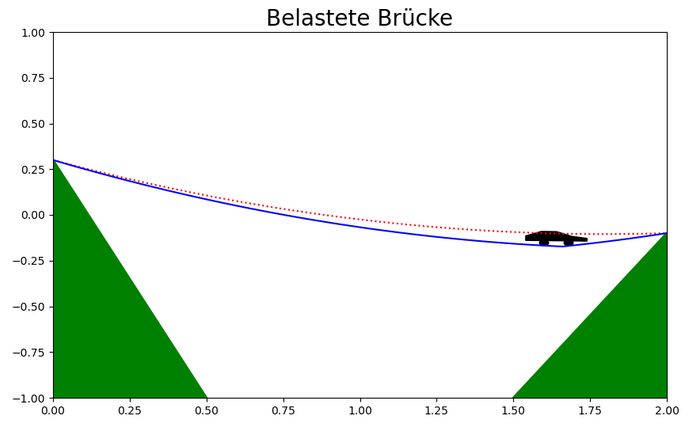

## Teil 1

Schreiben Sie in Python eine Routine `alpha, beta, gamma = lr(a,b,c)`, die die LR-Zerlegung einer Tridiagonalmatrix
$$
A = \begin{bmatrix}
          a_1 & b_1 & & &  \\
          c_2 & a_2 & b_2 & & \\
           & \ddots & \ddots & \ddots & \\
           & & c_{n-1} & a_{n-1} & b_{n-1}\\
           & & & c_n & a_n
     \end{bmatrix}
$$
berechnet.

Dabei stehen die Vektoren `a,b,c` für die Diagonal- bzw. Nebendiagonaleinträge von $A$. 
Die Vektoren `alpha, beta, gamma` sind die Einträge in den Faktoren der LR-Zerlegung, nämlich
$$
L = \begin{bmatrix}
                          1 & & & \\
                          \gamma_2 & 1 & & \\
                           & \ddots & \ddots & \\
                           & & \gamma_n & 1 
                         \end{bmatrix}, \quad R = \begin{bmatrix}
                                              \alpha_1 & \beta_1 & & \\
                                              & \ddots &\ddots & \\
                                               & & \alpha_{n-1} & \beta_{n-1} \\
                                                & & & \alpha_n  
                                             \end{bmatrix}.
$$

> **Hinweis**: Sie können die Struktur von $A$ verwenden, um Formeln für $\alpha_i$, $\beta_i$ und $\gamma_i$ zu erhalten. Multiplizieren Sie dazu $L \cdot R$ und vergleichen Sie die Einträge mit $A$, bzw. vergleichen Sie Aufgabe T3.2.

> **Hinweis**: Lösen Sie die Aufgabe so, dass keine $N \times N$-Matrizen angelegt werden, sondern arbeiten Sie nur mit Vektoren. Der Code kann dann für deutlich größere Probleme verwendet werden, da der Speicheraufwand nicht quadratisch, sondern nur linear wächst.

In [ ]:
def lr(a, b, c) :
    """
        Faktorisiere die Tridiagonalmatrix A, gegeben durch die drei Bänder 
        a (Hauptdiagonale), b (obere Nebendiagonale) und c (untere Nebendiagonale)
        in die Bänder alpha, beta und gamma (analog zu a, b, c) der beiden 
        2-Band-Matrizen L (gamma und EINS) und R (alpha und beta).
    """
    n = a.size
    
    alpha = ???
    ???
    
    return alpha, beta, gamma

## Teil 2

Schreiben Sie als nächstes eine Funktion `x = vorwaerts_rueckwaerts_substitution(alpha, beta, gamma, b)`, die die Lösung $x$ des Gleichungssystems $Ax = b$ bestimmt, in dem sie die LR-Faktorisierung `alpha, beta, gamma` von $A$ verwendet.

In [ ]:
def vorwaerts_rueckwaerts_substitution(alpha, beta, gamma, b):
    '''
        Vorwärts-Rückwaerts-Substitution zur Lösung des Tridiagonalsystems A * x = b
        mit Hilfe der LR-Zerlegung alpha, beta, gamma
    '''
    n = b.size
    x = np.copy(b)
    
    # Vorwärtssubstitution
    for i in range(1, n):
        x[i] ???
    
    # Rückwärtssubstitution
    ???

    return x

Sie sollen die Aufgabe oben natürlich lösen, ohne bereits fertige Methoden wie `lu_factor` oder `lu_solve` der Bibliothek Scipy zu verwenden. Trotzdem eignen sich diese gut als Test.

In [ ]:
def lr_scipy(A):
    LR, P = sp.linalg.lu_factor(A)
    return LR, P

def vorwaerts_rueckwaerts_substitution_scipy(LR, p, b):
    x = sp.linalg.lu_solve((LR, p), b)
    return x

## Testskript

Mit Ihrer Implementierung können wir nun berechnen, wie stark eine Hängebrücke belastet wird, wenn sie von einem Auto befahren wird. Die Situation lässt sich durch ein Gleichungssystem $Ax = b$ beschreiben, wobei die Einträge $b_i$ das Gewicht an der Stelle $i$ beschreiben, $x_i$ die gesuchte Auslenkung, und 
$A =
\begin{bmatrix}
    2  & -1     &        &    \\
    -1 & \ddots & \ddots &    \\
       & \ddots & \ddots & -1 \\
       &        &     -1 & 2
\end{bmatrix}$
eine Tridiagonalmatrix ist.

Als Vergleich berechnen wir das selbe Ergebnis mit den Scipy-Funktionen. Die Abweichung zu Ihrer Lösung sollte dabei nicht mehr als `1e-10` betragen.

In [ ]:
N = 100                       # Anzahl an Segmenten in der Brücke
h = 2/N                       # Länge der Segmente
gewicht_b = 0.25              # Gewicht der Brücke
gewicht_a = 0.005             # Gewicht des Autos
rand = np.array([0.3, -0.1])  # Randbedingungen

a = np.full(N - 1, 2.0)
b = np.full(N - 2, -1.0)
c = np.full(N - 2, -1.0)

# LGS faktorisieren
# unbelastete Brücke berechnen
alpha, beta, gamma = lr(a, b, c)
z = np.full(N-1, -gewicht_b * h**2)
z[0]  += rand[0]
z[-1] += rand[1]
x0 = np.hstack(
    [rand[0], vorwaerts_rueckwaerts_substitution(alpha, beta, gamma, z), rand[1]],
)

# Test Ihrer Lösung: Vergleich der unbelasteten Brücke via np.linalg.solve
A = np.diag(a) + np.diag(b, k=1) + np.diag(c, k=-1)
LR, p = lr_scipy(A)
x_scipy = vorwaerts_rueckwaerts_substitution_scipy(LR, p, z)
error = np.linalg.norm(x0[1:-1] - x_scipy, ord=np.inf)

print("Maximale Abweichung der Lösung vom Vergleichswert:")
print(error)

### Animation

In [ ]:
frames = 2*N - 8

plt.ioff()
fig = plt.figure(figsize=(10, 6))
plt.title(f'Belastete Brücke', fontsize=20)
fig.get_axes()[0].set(xlim=(0.0, 2.0), ylim=(-1.0, 1.0))
init_func = lambda: init_animation(x0, rand, N, h)
func = lambda frame: draw_frame(
    frame,
    rand,
    N,
    h,
    gewicht_b,
    gewicht_a,
    alpha,
    beta,
    gamma,
    vorwaerts_rueckwaerts_substitution,
)
anim = animation.FuncAnimation(
    fig=fig,
    func=func,
    frames=frames,
    init_func=init_func,
    interval=8000/N,
)
plt.ion()

from IPython.display import HTML
HTML(anim.to_jshtml())